In [1]:
# Cell 1: import library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import lightgbm as lgb 
import seaborn as sns
import json, time, warnings

from pathlib import Path

In [2]:
# Cell 2: load dataset and setup
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)

bm = json.loads(Path("../data/processed/features_blocks_meta.json").read_text())
H, LAST_DAY, TARGET = bm["H"], bm["LAST_DAY"], bm["TARGET"]
NUM_B , CAT_B = bm["NUM"], bm["CAT"]
FEATS_B = NUM_B + CAT_B
BLOCKS = {int(k): v for k, v in bm["blocks"].items()}
TEST_START = LAST_DAY - H + 1

# folds 3: the validation window right before the final test window
val_end = TEST_START - 1
val_start = val_end - H + 1
train_end = val_start - 1
print("fold 3: train_end", train_end, "| val", val_start, "to", val_end)

PARAMS = dict(objective="poisson", learning_rate=0.1, num_leaves=63, min_data_in_leaf=100,
              feature_fraction=0.8, bagging_fraction=0.8, bagging_freq=1,
              seed=42, verbose=-1, force_row_wise=True)
ROUNDS = 300

def family(f):
    if f.startswith("lag_k"):
        return "lags"
    if f.startswith(("roll_", "zero_rate")):
        return "rolling stats"
    if f.startswith("price") or f == "sell_price":
        return "price"
    if f in ("dow", "dom", "woy", "month", "is_weekend", "age"):
        return "calendar / age"
    if f in ("snap", "is_christmas", "has_event") or f.startswith("event_"):
        return "events / SNAP"
    return "item / category"

FAM = pd.Series({f: family(f) for f in FEATS_B})
print(FAM.value_counts().to_string())
print("features:", len(FEATS_B)) 

fold 3: train_end 1885 | val 1886 to 1913
rolling stats      7
events / SNAP      7
calendar / age     6
price              5
lags               5
item / category    3
features: 33


In [3]:
# Cell 3: Train two block models and compute SHAP
res = {}
for b in (1, 4):
    s = BLOCKS[b]
    t0 = time.time()
    tbl = pd.read_parquet(Path(f"../data/processed/features_s{s}.parquet"), columns=["d_num", "sales"] + FEATS_B)
    d0, d1 = val_start + 7 * (b - 1), val_start + 7 * b - 1
    assert d1 - s <= train_end, "features would reach beyond the cutoff"
    train = tbl[tbl["d_num"] <= train_end]
    val = tbl[(tbl["d_num"] >= d0) & (tbl["d_num"] <= d1)].reset_index(drop=True)

    dtrain = lgb.Dataset(train[FEATS_B], label=train["sales"],
                         categorical_feature=CAT_B, free_raw_data=True)
    booster = lgb.train(PARAMS, dtrain, num_boost_round=ROUNDS)

    raw = booster.predict(val[FEATS_B], raw_score=True)
    contrib = booster.predict(val[FEATS_B], pred_contrib=True)        # last column = base value
    err = float(np.abs(contrib.sum(axis=1) - raw).max())

    res[b] = {"X": val[FEATS_B], "y": val["sales"].to_numpy(), "shap": contrib[:, :-1],
              "base": float(contrib[0, -1]), "raw": raw}
    print(f"block {b} (shift {s}): rows {len(val)} | max additivity error {err:.2e} | "
          f"mean predicted {np.exp(raw).mean():.3f} vs mean actual {val['sales'].mean():.3f} | "
          f"{time.time() - t0:.0f}s")
    del dtrain, booster, tbl, train

block 1 (shift 7): rows 21343 | max additivity error 1.87e-14 | mean predicted 1.540 vs mean actual 1.521 | 63s
block 4 (shift 28): rows 21343 | max additivity error 1.75e-14 | mean predicted 1.462 vs mean actual 1.483 | 60s


shares add up to: {'block 1': 100.0, 'block 4': 100.0}
top 15 features by share of mean |SHAP| (%):


,family,block 1,block 4
roll_mean_14,rolling stats,23.3,19.6
item_id,item / category,12.2,16.2
roll_mean_28,rolling stats,13.9,12.3
roll_mean_56,rolling stats,5.7,10.0
dow,calendar / age,7.3,7.9
dept_id,item / category,3.6,7.0
roll_mean_7,rolling stats,10.0,5.4
sell_price,price,1.8,3.2
lag_k0,lags,3.0,2.8
zero_rate_28,rolling stats,2.3,2.4



share by family (%):


,block 1,block 4
rolling stats,60.6,52.2
item / category,16.5,24.1
calendar / age,13.6,13.0
price,3.7,5.9
lags,4.1,3.5
events / SNAP,1.5,1.2


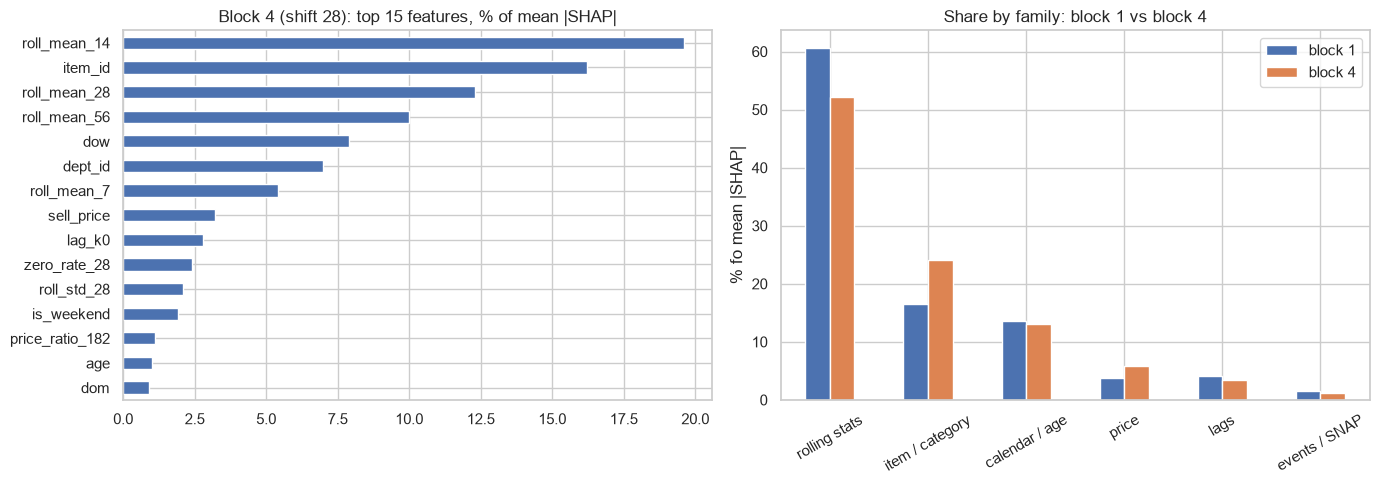

In [5]:
# Cell 4: Global importance by feature and by family
imp = pd.DataFrame({f"block {b}": np.abs(res[b]["shap"]).mean(axis=0) for b in res}, index = FEATS_B)
share = imp / imp.sum() * 100
print("shares add up to:", share.sum().round(1).to_dict())

top = share.sort_values("block 4", ascending=False).head(15).round(1)
top.insert(0, "family", FAM.reindex(top.index))
print("top 15 features by share of mean |SHAP| (%):")
display(top)

fam = share.groupby(FAM).sum().sort_values("block 4", ascending=False).round(1)
print("\nshare by family (%):")
display(fam)

fig, ax = plt.subplots(1, 2, figsize= (14, 5))
top["block 4"].iloc[::-1].plot(kind="barh", ax=ax[0])
ax[0].set_title("Block 4 (shift 28): top 15 features, % of mean |SHAP|")
fam.plot(kind="bar", ax=ax[1])
ax[1].set_title("Share by family: block 1 vs block 4")
ax[1].set_ylabel("% fo mean |SHAP|")
ax[1].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

In [6]:
# Cell 4: Events and SNAP in these windows, weekday effect, price ratio effect
fi = {f: i for i, f in enumerate(FEATS_B)}
ev_idx = [fi[f] for f in FEATS_B if FAM[f] == "events / SNAP"]
dnames = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

for b in res:
    X, S = res[b]["X"], res[b]["shap"]
    print(f"\n==== block {b} =====")
    print("rows with an event:", int((X["has_event"] == 1).sum()),
          "| SNAP rows:", int((X["snap"] == 1).sum()),
          "| Christmas rows:", int((X["is_christmas"] == 1).sum()))

    ev_abs = np.abs(S[:, ev_idx]).sum(axis=1)
    for name, mask in (("events rows", X["has_event"] == 1), ("SNAP rows", X["snap"] == 1)):
        m = mask.to_numpy()
        if m.sum() > 0:
            print(f"events/SNAP family, mean |SHAP| or {name}: {ev_abs[m].mean():.3f} | other rows: {ev_abs[~m].mean():.3f}")

    g = pd.DataFrame({"dow": X["dow"].to_numpy(), "shap": S[:, fi["dow"]]}).groupby("dow")["shap"].mean()
    display(pd.DataFrame({"day": [dnames[i] for i in g.index], "mean SHAP": g.values.round(3),
                          "factor exp(SHAP)": np.exp(g.values).round(3)}, index = g.index))

    r = X["price_ratio_182"].astype("float64")
    pb = pd.cut(r, bins=[0, 0.9, 0.97, 1.03, 1.1, 10],
                labels=["<0.90", "0.90-0.97", "0.97-1.03", "1.03-1.10", ">1.10"])
    display(pd.DataFrame({"bin": pb, "shap": S[:, fi["price_ratio_182"]]})
            .groupby("bin", observed=True)["shap"].agg(["size", "mean"]).round(3))


==== block 1 =====
rows with an event: 0 | SNAP rows: 9147 | Christmas rows: 0
events/SNAP family, mean |SHAP| or SNAP rows: 0.027 | other rows: 0.020


,day,mean SHAP,factor exp(SHAP)
dow,,,
0,Mon,-0.048,0.953
1,Tue,-0.119,0.888
2,Wed,-0.125,0.883
3,Thu,-0.121,0.886
4,Fri,0.041,1.042
5,Sat,0.173,1.189
6,Sun,0.181,1.198


,size,mean
bin,,
<0.90,59,0.099
0.90-0.97,693,0.052
0.97-1.03,20003,-0.002
1.03-1.10,470,0.011
>1.10,118,0.013



==== block 4 =====
rows with an event: 0 | SNAP rows: 0 | Christmas rows: 0


,day,mean SHAP,factor exp(SHAP)
dow,,,
0,Mon,-0.042,0.959
1,Tue,-0.121,0.886
2,Wed,-0.125,0.882
3,Thu,-0.124,0.883
4,Fri,0.038,1.039
5,Sat,0.180,1.197
6,Sun,0.187,1.206


,size,mean
bin,,
<0.90,49,0.199
0.90-0.97,681,0.131
0.97-1.03,20132,-0.006
1.03-1.10,355,0.042
>1.10,126,-0.008


In [8]:
# Cell 5: all five price features together
price_idx = [fi[f] for f in FEATS_B if FAM[f] == "price"]
for b in res:
    X, S = res[b]["X"], res[b]["shap"]
    r = X["price_ratio_182"].astype("float64")
    pb = pd.cut(r, bins=[0, 0.9, 0.97, 1.03, 1.1, 10],
                labels=["<0.90", "0.90-0.97", "0.97-1.03", "1.03-1.10", ">1.10"])
    print(f"block {b}: summed SHAP of all 5 price features, by price_ratio_182 bin")
    display(pd.DataFrame({"bin": pb, "price family": S[:, price_idx].sum(axis=1)})
              .groupby("bin", observed=True)["price family"].agg(["size", "mean"]).round(3))

block 1: summed SHAP of all 5 price features, by price_ratio_182 bin


,size,mean
bin,,
<0.90,59,0.364
0.90-0.97,693,0.191
0.97-1.03,20003,-0.002
1.03-1.10,470,0.038
>1.10,118,0.161


block 4: summed SHAP of all 5 price features, by price_ratio_182 bin


,size,mean
bin,,
<0.90,49,0.364
0.90-0.97,681,0.205
0.97-1.03,20132,-0.003
1.03-1.10,355,0.030
>1.10,126,0.135


## Summary of Notebook 08: explainability (SHAP)

**Setup**
- Model: Poisson, item_id, 63 leaves, 300 rounds (the chosen model), trained on fold 3 data (rows up to d_1885)
- Blocks 1 (features shifted by 7 days) and 4 (shifted by 28 days), explained on their own validation rows (21,343 rows each, d_1886-1892 and d_1907-1913)
- SHAP from LightGBM pred_contrib; values are on the log scale of the predicted mean (exp(SHAP) = multiplicative factor); additivity check passed (max error 1.8e-14); mean prediction 1.54 / 1.46 vs mean actual 1.52 / 1.48

**Share of mean |SHAP| by family (%)**

| Family | Block 1 | Block 4 |
|---|---|---|
| rolling stats | 60.6 | 52.2 |
| item / category | 16.5 | 24.1 |
| calendar / age | 13.6 | 13.0 |
| price | 3.7 | 5.9 |
| lags | 4.1 | 3.5 |
| events / SNAP | 1.5 | 1.2 |

**Findings**
- Recent sales level dominates: roll_mean_14 is the top feature in both blocks (23.3% / 19.6%), then roll_mean_28
- Fresher history shifts weight to the short window (roll_mean_7: 10.0% vs 5.4%); stale history shifts it to long windows and item identity (roll_mean_56 5.7% -> 10.0%, item_id 12.2% -> 16.2%)
- Weekday is the strongest calendar signal (dow 7-8%); factors: Sunday 1.20, Saturday 1.19-1.20, Friday 1.04, Monday 0.95-0.96, Tuesday-Thursday 0.88-0.89; same ordering as the EDA, same in both blocks
- Price cuts raise the prediction: price_ratio_182 below 0.90 gives +10% (block 1) and +22% (block 4); no matching drop for price rises in this feature (few rows; other price features not summed)
- Price (all five price features summed): cuts raise the prediction (+44% for price_ratio_182 below 0.90, +21-23% for 0.90-0.97), but the tails are not reliable: for cuts the model under-predicts actual sales (by 27-31% on 49-59 rows), and for ratios above 1.10 it pushes the prediction up (+14-17%) and over-predicts actual sales by about 23% (118-126 rows); the EDA's drop for price rises is not reproduced. About 97% of rows sit between 0.90 and 1.03, where predictions are within about 6% of actuals.
- item_id is heavily used (12-16%) but adds only a small accuracy gain (WAPE 0.744 -> 0.739): it overlaps with the rolling means, which also describe an item's level

**Limits (for the README)**
- One fold, one week of rows per block, one trained model per block
- The validation windows contain no event days and no Christmas; SNAP appears only in block 1 (3 days); event effects could not be assessed here
- SHAP describes what the model uses, not what causes sales; correlated features share credit (five lags, seven rolling stats)

In [9]:
# Cell 6: is the model right on those rows?
labels = ["<0.90", "0.90-0.97", "0.97-1.03", "1.03-1.10", ">1.10"]
for b in res:
    X, y, pred = res[b]["X"], res[b]["y"], np.exp(res[b]["raw"])
    pb = pd.cut(X["price_ratio_182"].astype("float64"), bins=[0, 0.9, 0.97, 1.03, 1.1, 10], labels=labels)
    print(f"block {b}: mean actual vs mean predicted, by price_ratio_182 bin")
    display(pd.DataFrame({"bin": pb, "actual": y, "predicted": pred})
              .groupby("bin", observed=True)
              .agg(rows=("actual", "size"), actual=("actual", "mean"), predicted=("predicted", "mean"))
              .round(3))

block 1: mean actual vs mean predicted, by price_ratio_182 bin


,rows,actual,predicted
bin,,,
<0.90,59,2.678,1.855
0.90-0.97,693,1.618,1.709
0.97-1.03,20003,1.489,1.497
1.03-1.10,470,2.353,2.703
>1.10,118,2.534,3.108


block 4: mean actual vs mean predicted, by price_ratio_182 bin


,rows,actual,predicted
bin,,,
<0.90,49,2.490,1.816
0.90-0.97,681,1.583,1.643
0.97-1.03,20132,1.475,1.448
1.03-1.10,355,1.299,1.384
>1.10,126,2.246,2.753
